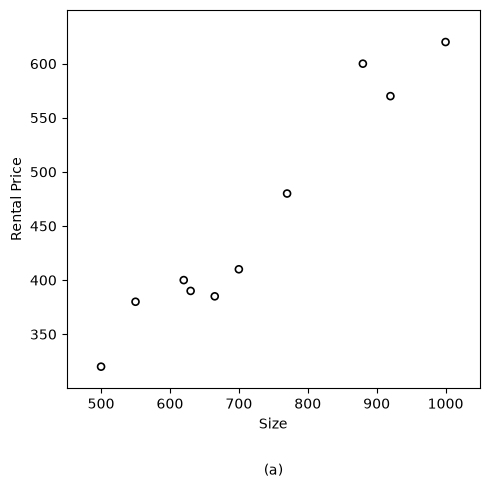

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

data_path = "/home/willieloea/Laboratory/datasets/foml_datasets/tab7_1.csv"
df = pd.read_csv(data_path)

sizes = df["SIZE"]
prices = df["RENTAL PRICE"]

# 2. Create the figure and axis
fig, ax = plt.subplots(figsize=(5, 5))

# In the book, points are drawn as open circles with black outlines
ax.scatter(sizes, prices, facecolors="none", edgecolors="black", s=25, linewidths=1.2)

# 3. Configure axes limits and labels to match Figure 7.1(a)
ax.set_xlabel("Size", fontsize=10)
ax.set_ylabel("Rental Price", fontsize=10)

ax.set_xlim(450, 1050)
ax.set_ylim(300, 650)

# Optional: set exact ticks as seen in the book
ax.set_xticks([500, 600, 700, 800, 900, 1000])
ax.set_yticks([350, 400, 450, 500, 550, 600])

plt.title("(a)", y=-0.25, fontsize=10)
plt.tight_layout()

# 4. Display or save
plt.show()


In [2]:
def sse(targets, predictions):
    """Calculates the sum of squared errors between targets and predictions
    
    targets is a list containing the target values of the training data.
    predictions is a list of predictions made by the model."""
    errors = [t-p for t,p in zip(targets, predictions)]
    squared_errors = [error**2 for error in errors]
    sum_squared_errors = 0.5*sum(squared_errors)
    return sum_squared_errors

class LinearRegressionModel:
    def __init__(self, slope, intercept):
        self.slope = slope
        self.intercept = intercept

    def predict(self, query):
        return self.intercept + self.slope * query

intercept = 6.47
slopes = [0.4, 0.5, 0.62, 0.7, 0.8]

for slope in slopes:
    model = LinearRegressionModel(slope, intercept)
    predictions = [model.predict(q) for q in df["SIZE"]]
    targets = df["RENTAL PRICE"]

    print(f"For slope = {slope}, the sse is: {sse(targets, predictions)}")

For slope = 0.4, the sse is: 136213.13449999996
For slope = 0.5, the sse is: 42709.30449999998
For slope = 0.62, the sse is: 2837.078499999999
For slope = 0.7, the sse is: 20093.394500000006
For slope = 0.8, the sse is: 90981.31450000004


In [3]:
import math

def float_range(*args):
    start = stop = step = None
    if len(args) == 1:
        start = 0
        stop = args[0]
        step = 1.0
    elif len(args) == 2:
        start = args[0]
        stop = args[1]
        step = 1.0
    elif len(args) == 3:
        start = args[0]
        stop = args[1]
        step = args[2]
    else:
        raise TypeError(f"range expected at most 3 arguments, got {len(args)}")

    while start < stop:
        yield round(start, 5)
        start += step

intercepts = list(float_range(-10, 20, 0.1))
slopes = list(float_range(-2, 3, 0.1))

minimum = math.inf
min_intercept = min_slope = None

for intercept in intercepts:
    for slope in slopes:
        model = LinearRegressionModel(slope, intercept)

        predictions = [model.predict(q) for q in df["SIZE"]]
        targets = df["RENTAL PRICE"]

        sse_result = sse(targets, predictions)
        if sse_result < minimum:
            min_intercept = intercept
            min_slope = slope
            minimum = sse_result

print("Min Intercept:", min_intercept)
print("Min Slope:", min_slope)

Min Intercept: 20.0
Min Slope: 0.6


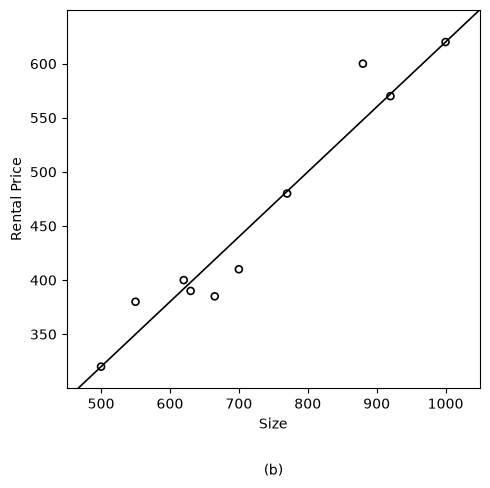

In [4]:
# 3. Create the model with the parameters from Equation (7.2)
model = LinearRegressionModel(slope=min_slope, intercept=min_intercept)

# 4. Generate points for the line
# We pick x-values covering the range of the x-axis
x_line = [450, 1050]
y_line = [model.predict(x) for x in x_line]

# 5. Plot
fig, ax = plt.subplots(figsize=(5, 5))

# Plot the data points (open circles with black edges)
ax.scatter(sizes, prices, facecolors="none", edgecolors="black", s=25, linewidths=1.2)

# Plot the regression line
ax.plot(x_line, y_line, color="black", linewidth=1.2)

# Set axes limits, ticks, and labels to match Figure 7.1(b)
ax.set_xlabel("Size", fontsize=10)
ax.set_ylabel("Rental Price", fontsize=10)

ax.set_xlim(450, 1050)
ax.set_ylim(300, 650)

ax.set_xticks([500, 600, 700, 800, 900, 1000])
ax.set_yticks([350, 400, 450, 500, 550, 600])

plt.title("(b)", y=-0.25, fontsize=10)
plt.tight_layout()

plt.show()

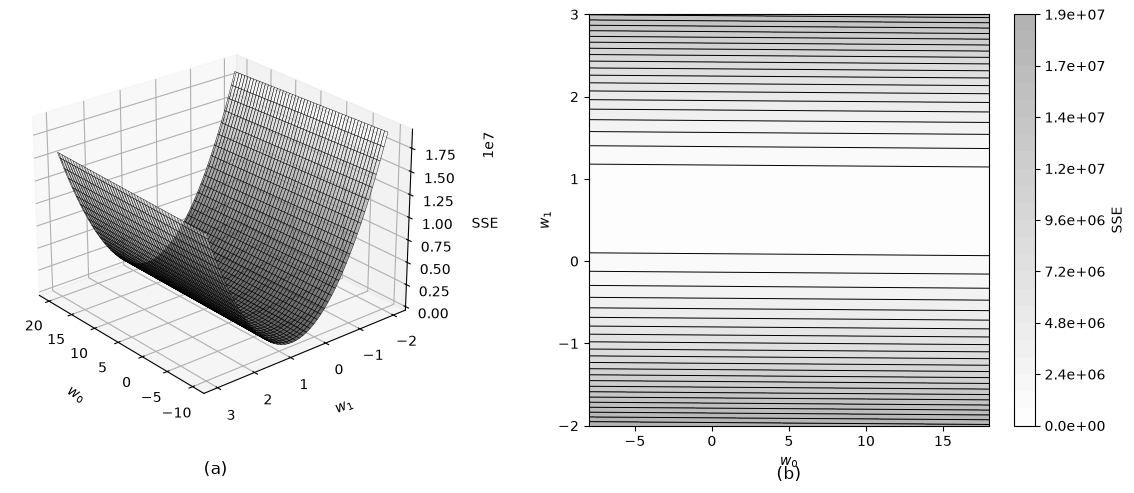

In [5]:
import numpy as np

# 1. Load data
x_data = df["SIZE"].values  # Feature values
t_data = df["RENTAL PRICE"].values  # Actual target values

# 2. Define the ranges for w0 (intercept) and w1 (slope)
# The book specifies w0 in [-10, 20] and w1 in [-2, 3]
w0_vals = np.linspace(-10, 20, 100)
w1_vals = np.linspace(-2, 3, 100)

# Create coordinate matrices (grid)
W0, W1 = np.meshgrid(w0_vals, w1_vals)

# 3. Vectorized SSE calculation
# For each (w0, w1), predictions are: w0 + w1 * x_i
# We expand dimensions so the calculation happens across the entire grid at once:
# Shape of W0, W1: (100, 100) -> add axis for instances -> (100, 100, 1)
# Shape of x_data: (10,) -> (1, 1, 10)
preds = W0[:, :, np.newaxis] + W1[:, :, np.newaxis] * x_data[np.newaxis, np.newaxis, :]
targets = t_data[np.newaxis, np.newaxis, :]

# L2 loss: 0.5 * sum((target - prediction)^2) over all instances
SSE = 0.5 * np.sum((targets - preds) ** 2, axis=2)

# 4. Plotting Figure 7.3 (a) and (b)
fig = plt.figure(figsize=(12, 5))

# --- (a) 3D Surface Plot ---
ax1 = fig.add_subplot(1, 2, 1, projection="3d")
# Plot wireframe/surface with subtle shading like the textbook
surf = ax1.plot_surface(
    W0,
    W1,
    SSE,
    cmap="gray",
    edgecolor="black",
    linewidth=0.3,
    alpha=0.6,
    antialiased=True,
)

ax1.set_xlabel(r"$w_0$", labelpad=10)
ax1.set_ylabel(r"$w_1$", labelpad=10)
ax1.set_zlabel("SSE", labelpad=10)
ax1.set_title("(a)", y=-0.15)
ax1.view_init(elev=25, azim=140)  # Viewing angle similar to Figure 7.3(a)

# --- (b) Bird's-eye Contour Plot ---
ax2 = fig.add_subplot(1, 2, 2)
# Draw filled contours with horizontal lines
contours = ax2.contour(W0, W1, SSE, levels=30, colors="black", linewidths=0.7)
contourf = ax2.contourf(W0, W1, SSE, levels=30, cmap="gray_r", alpha=0.3)

cbar = fig.colorbar(contourf, ax=ax2, format="%.1e")
cbar.set_label("SSE")

ax2.set_xlabel(r"$w_0$")
ax2.set_ylabel(r"$w_1$")
ax2.set_xlim(-8, 18)
ax2.set_ylim(-2, 3)
ax2.set_title("(b)", y=-0.15)

plt.tight_layout()
plt.show()

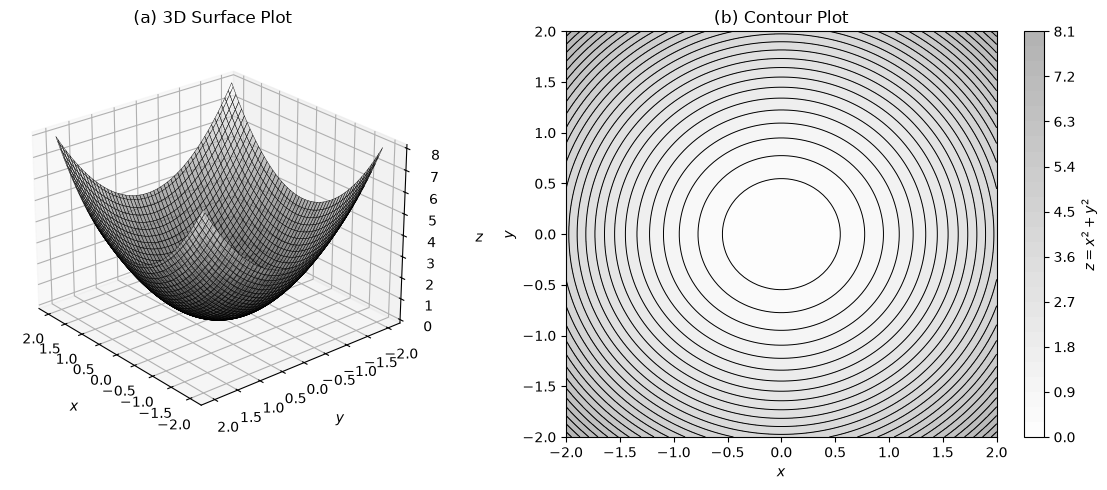

In [6]:
import numpy as np

# 2. Define the ranges for x and y
x_vals = np.linspace(-2, 2, 100)
y_vals = np.linspace(-2, 2, 100)

# Create coordinate matrices (grid)
X, Y = np.meshgrid(x_vals, y_vals)

# 3. Calculate Z = X^2 + Y^2 directly on the grid
Z = X**2 + Y**2

# 4. Plotting Figure 7.3 (a) and (b)
fig = plt.figure(figsize=(12, 5))

# --- (a) 3D Surface Plot ---
ax1 = fig.add_subplot(1, 2, 1, projection="3d")
# Plot wireframe/surface with subtle shading like the textbook
surf = ax1.plot_surface(
    X,
    Y,
    Z,
    cmap="gray",
    edgecolor="black",
    linewidth=0.3,
    alpha=0.6,
    antialiased=True,
)

ax1.set_xlabel(r"$x$", labelpad=10)
ax1.set_ylabel(r"$y$", labelpad=10)
ax1.set_zlabel(r"$z$", labelpad=10)
ax1.set_title("(a) 3D Surface Plot")
ax1.view_init(elev=25, azim=140)

# --- (b) Bird's-eye Contour Plot ---
ax2 = fig.add_subplot(1, 2, 2)
# Draw filled contours with horizontal lines
contours = ax2.contour(X, Y, Z, levels=30, colors="black", linewidths=0.7)
contourf = ax2.contourf(X, Y, Z, levels=30, cmap="gray_r", alpha=0.3)

cbar = fig.colorbar(contourf, ax=ax2)
cbar.set_label(r"$z = x^2 + y^2$")

ax2.set_xlabel(r"$x$")
ax2.set_ylabel(r"$y$")
ax2.set_xlim(-2, 2)
ax2.set_ylim(-2, 2)
ax2.set_title("(b) Contour Plot")

plt.tight_layout()
plt.show()

Batch Gradient Descent:

Algorithm 4 The gradient descent algorithm for training multivariable linear regression models.

Require: set of training instances $\mathcal{D}$  
Require: a learning rate $\alpha$ that controls how quickly the algorithm converges  
Require: a function, $\textit{errorDelta}$, that determines the direction in which to adjust a given weight, $w_j$, so as to move down the slope of an error surface determined by the dataset, $\mathcal{D}$  
Require: a convergence criterion that indicates that the algorithm has completed

1: $\mathbf{w} \leftarrow$ random starting point in the weight space  
2: repeat  
3:      for each $w_j$ in $\mathbf{w}$ do  
4:        $w_j \leftarrow w_j + \alpha \cdot \textit{errorDelta}(\mathcal{D},w_j)$  
5:    end for  
6: until convergence occurs

In [ ]:
import random

dataset = []
for _, row in df.iterrows():
    descriptive = [
        1.0, 
        float(row["SIZE"]),
        float(row["FLOOR"]),
        float(row["BROADBAND RATE"])
    ]
    target = row["RENTAL PRICE"]
    dataset.append((descriptive, target))

def dot_product(w, d):
    return sum(wi*di for wi, di in zip(w,d))

def sse(dataset, w):
    return 0.5 * sum([(t_i - dot_product(w,d_i))**2 for (d_i,t_i) in dataset])

def error_delta(dataset, predictions, j):
    total_delta = sum([(t - pred) * d_i[j] for (d_i, t), pred in zip(dataset, predictions)])
    return total_delta

def gradient_descent(
        dataset,
        alpha,
        iterations
    ):
    """Gradient descent for multivariable linear gradient descent

    :param dataset: list of tuples ([d0, d1, ..., dm], target)
    :param alpha: the learning rate
    :param error_delta: a function that determines the update direction
    :param iterations: how many iterations to descend
    """

    # random initialization
    w = [random.uniform(-0.2, 0.2) for _ in range(len(dataset[0][0]))]

    for _ in range(iterations):
        predictions = [dot_product(w,d_i) for d_i,_ in dataset]
        new_w = []
        for j, w_j in enumerate(w):
            w_j = w_j + alpha * error_delta(dataset, predictions, j)
            new_w.append(w_j)
        w = new_w

    return w

weights = gradient_descent(dataset, alpha=2e-8, iterations=10000)
print("Trained weights:", [round(x, 4) for x in weights])
print("Final SSE:", round(sse(dataset, weights), 2))


Trained weights: [-0.0171, 0.6296, -0.039, -0.0]
Final SSE: 2854.49


In [ ]:
# 100 iterations
# Trained weights: [-0.0606, 0.6357, -0.1285, -0.1327]
# Final SSE: 2963.87

Index(['ID', 'SIZE', 'FLOOR', 'BROADBAND RATE', 'ENERGY RATING',
       'RENTAL PRICE'],
      dtype='str')

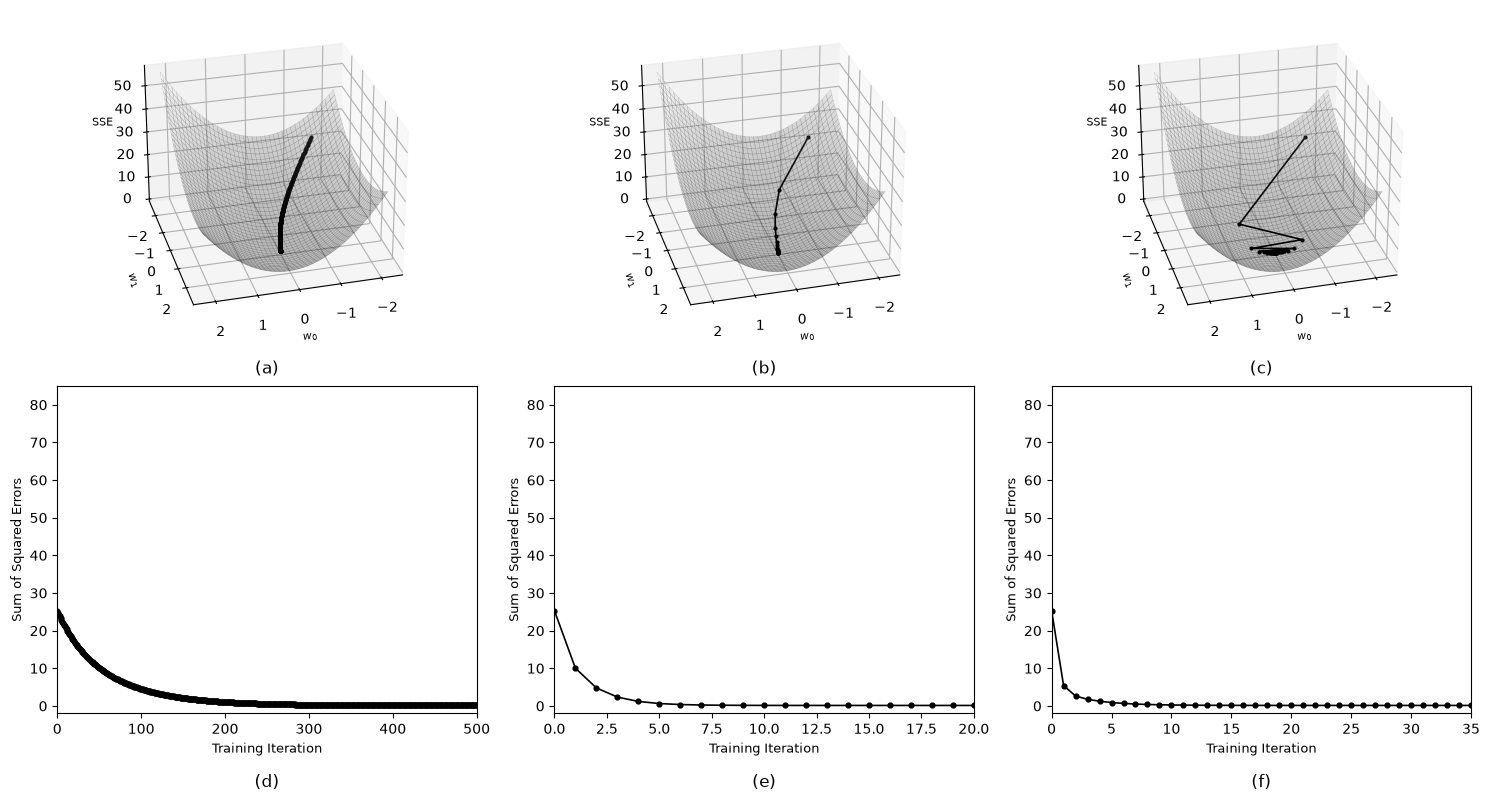

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


# 1. Helper function for [-1, 1] range normalization (Footnote 8)
def normalize_to_minus_one_to_one(series):
    min_v = series.min()
    max_v = series.max()
    return 2.0 * (series - min_v) / (max_v - min_v) - 1.0


# 2. Normalize dataset
x_norm = normalize_to_minus_one_to_one(df["SIZE"]).values
t_norm = normalize_to_minus_one_to_one(df["RENTAL PRICE"]).values

# Format training instances: ([1.0, x_i], target_i)
dataset = [([1.0, float(x)], float(t)) for x, t in zip(x_norm, t_norm)]


# 3. SSE calculation
def compute_sse(dataset, w):
    return 0.5 * sum((t - (w[0] + w[1] * d[1])) ** 2 for d, t in dataset)


# 4. Gradient descent tracking the path (w0, w1, SSE)
def gradient_descent_trajectory(dataset, alpha, iterations, initial_w):
    w = list(initial_w)
    path_w0 = [w[0]]
    path_w1 = [w[1]]
    path_sse = [compute_sse(dataset, w)]

    for _ in range(iterations):
        # Predictions for current weights
        preds = [w[0] + w[1] * d[1] for d, _ in dataset]

        # Calculate error deltas (Equation 7.16)
        delta_0 = sum((t - p) * 1.0 for (_, t), p in zip(dataset, preds))
        delta_1 = sum((t - p) * d[1] for (d, t), p in zip(dataset, preds))

        # Update weights (Equation 7.17)
        w[0] += alpha * delta_0
        w[1] += alpha * delta_1

        path_w0.append(w[0])
        path_w1.append(w[1])
        path_sse.append(compute_sse(dataset, w))

    return path_w0, path_w1, path_sse


# 5. Precompute error surface grid for 3D plots
w0_vals = np.linspace(-2.2, 2.2, 80)
w1_vals = np.linspace(-2.5, 2.5, 80)
W0, W1 = np.meshgrid(w0_vals, w1_vals)

preds_grid = (
    W0[:, :, np.newaxis] + W1[:, :, np.newaxis] * x_norm[np.newaxis, np.newaxis, :]
)
SSE_grid = 0.5 * np.sum(
    (t_norm[np.newaxis, np.newaxis, :] - preds_grid) ** 2, axis=2
)

# 6. Configuration matching Figure 7.7
# Initial weights chosen high on the rim (SSE ~ 75)
initial_w = [-1.5, -2.0]

experiments = [
    {"alpha": 0.002, "iters": 500, "lbl_3d": "(a)", "lbl_2d": "(d)"},
    {"alpha": 0.08, "iters": 20, "lbl_3d": "(b)", "lbl_2d": "(e)"},
    {"alpha": 0.18, "iters": 35, "lbl_3d": "(c)", "lbl_2d": "(f)"},
]

# 7. Create 2x3 Subplot Grid
fig = plt.figure(figsize=(15, 8))

for idx, exp in enumerate(experiments):
    w0_path, w1_path, sse_path = gradient_descent_trajectory(
        dataset, exp["alpha"], exp["iters"], initial_w
    )

    # --- Top Row: 3D Surface with Trajectory ---
    ax_3d = fig.add_subplot(2, 3, idx + 1, projection="3d")
    ax_3d.plot_surface(
        W0,
        W1,
        SSE_grid,
        cmap="gray",
        alpha=0.25,
        edgecolor="black",
        linewidth=0.2,
    )

    # Plot path on the surface
    ax_3d.plot(
        w0_path,
        w1_path,
        sse_path,
        color="black",
        linewidth=1.2,
        marker="o",
        markersize=2,
    )
    ax_3d.set_xlabel(r"$w_0$", labelpad=2, fontsize=8)
    ax_3d.set_ylabel(r"$w_1$", labelpad=2, fontsize=8)
    ax_3d.set_zlabel("SSE", labelpad=2, fontsize=8)
    ax_3d.view_init(elev=28, azim=75)
    ax_3d.set_title(exp["lbl_3d"], y=-0.15)

    # --- Bottom Row: SSE vs Training Iteration ---
    ax_2d = fig.add_subplot(2, 3, idx + 4)
    iters = list(range(len(sse_path)))

    ax_2d.plot(iters, sse_path, color="black", linewidth=1.2)
    ax_2d.scatter(iters, sse_path, color="black", s=12)

    ax_2d.set_xlabel("Training Iteration", fontsize=9)
    ax_2d.set_ylabel("Sum of Squared Errors", fontsize=9)
    ax_2d.set_ylim(-2, 85)
    ax_2d.set_xlim(0, exp["iters"])
    ax_2d.set_title(exp["lbl_2d"], y=-0.25)

plt.tight_layout()
plt.show()